# Notebook 00: Complete Hourly Data Representation & Issue Audit
## 1. Load Raw Hourly CSV & Multi-Modal NPZ

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
df = pd.read_csv(PROJECT_ROOT / '06_Data' / 'riyadh_line_a_tabular_features.csv', low_memory=False)
df['ts'] = pd.to_datetime(df['time']).dt.tz_localize(None)
df = df.sort_values('ts').reset_index(drop=True)
npz = np.load(PROJECT_ROOT / '06_Data' / 'line_b_final_dataset.npz', allow_pickle=True)
print(f'Hourly CSV: {df.shape} | Span: {df["ts"].min()} -> {df["ts"].max()}')
print('NPZ keys:', {k: npz[k].shape for k in npz.keys()})

Hourly CSV: (87456, 114) | Span: 2015-01-02 00:00:00 -> 2024-12-23 23:00:00
NPZ keys: {'nwp_grid': (400, 6, 16, 16), 'satellite_grid': (400, 3, 32, 32), 'node_features': (400, 6, 12), 'seq_features': (400, 24, 6, 12), 'targets_pm10': (400, 6, 6), 'hazard_classes': (400, 6, 6), 'adjacency_matrix': (6, 6)}


## 2. Four-Modality Feature Taxonomy

In [2]:
modalities = {'Ground_METAR': [c for c in df.columns if c in ['tmpc','dwpc','drct','sknt','gust','vsby','mslp','wind_speed_ms','wind_gust_ms','visibility_km','relative_humidity','pm10_calibrated_ugm3']], 'ERA5_Reanalysis': [c for c in df.columns if c.startswith('era5_') or c.startswith('phys_')], 'Satellite_AOD': [c for c in df.columns if c.startswith('sat_')], 'CAMS_NWP': [c for c in df.columns if 'cams' in c or 'nwp' in c]}
for k, v in modalities.items():
    print(f'{k:18s}: {len(v):2d} columns')

Ground_METAR      : 12 columns
ERA5_Reanalysis   : 23 columns
Satellite_AOD     :  8 columns
CAMS_NWP          :  2 columns


## 3. Raw Hourly Missingness Audit (`mslp` 100% NaN, `wxcodes` 92.3% Blank)

In [3]:
miss = (df.isna().mean() * 100).sort_values(ascending=False)
print(miss.head(10).round(2).to_string())

mslp            100.00
wxcodes          92.27
station_name      0.41
station           0.41
valid             0.41
role              0.41
hazard_level      0.41
time              0.00
lat               0.00
lon               0.00


## 4. Missingness Bar Chart

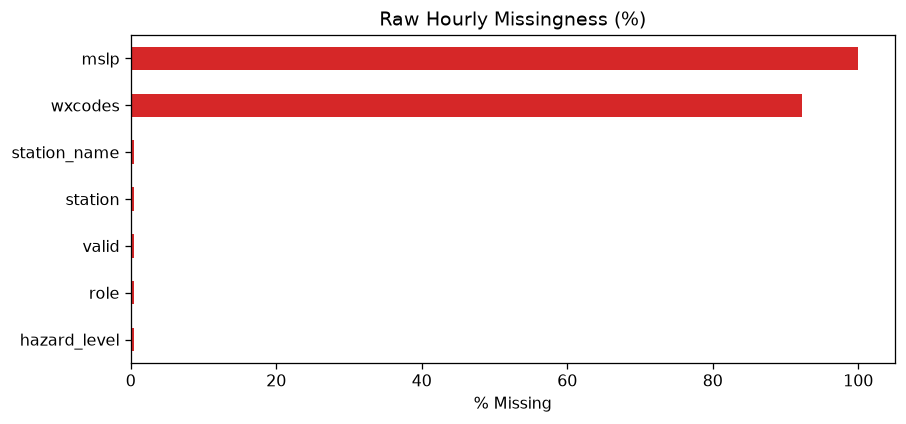

In [4]:
top_m = miss[miss > 0].head(10)
fig, ax = plt.subplots(figsize=(8, 3.8))
if len(top_m) > 0: top_m.iloc[::-1].plot(kind='barh', ax=ax, color='#d62728')
ax.set_title('Raw Hourly Missingness (%)'); ax.set_xlabel('% Missing'); plt.tight_layout()

## 5. Issue 1 Audit: 10 km METAR Visibility Cap & `53.7 ug/m3` Floor

In [5]:
cap_pct = (df['visibility_km'] >= 9.9).mean() * 100
flr_pct = (df['pm10_calibrated_ugm3'] <= 54.0).mean() * 100
print(f'Hourly visibility >= 9.9 km (capped): {cap_pct:.1f}%')
print(f'Hourly PM10 proxy <= 54 ug/m3 (floor): {flr_pct:.1f}%')
print('Hourly PM10 quantiles:', df['pm10_calibrated_ugm3'].quantile([0.1,0.25,0.5,0.75,0.9,0.99]).round(2).to_dict())

Hourly visibility >= 9.9 km (capped): 78.1%
Hourly PM10 proxy <= 54 ug/m3 (floor): 79.1%
Hourly PM10 quantiles: {0.1: 53.7, 0.25: 53.7, 0.5: 53.7, 0.75: 53.7, 0.9: 72.7, 0.99: 877.2}


## 6. Hourly Proxy Histogram Showing the `53.7` Floor Spike

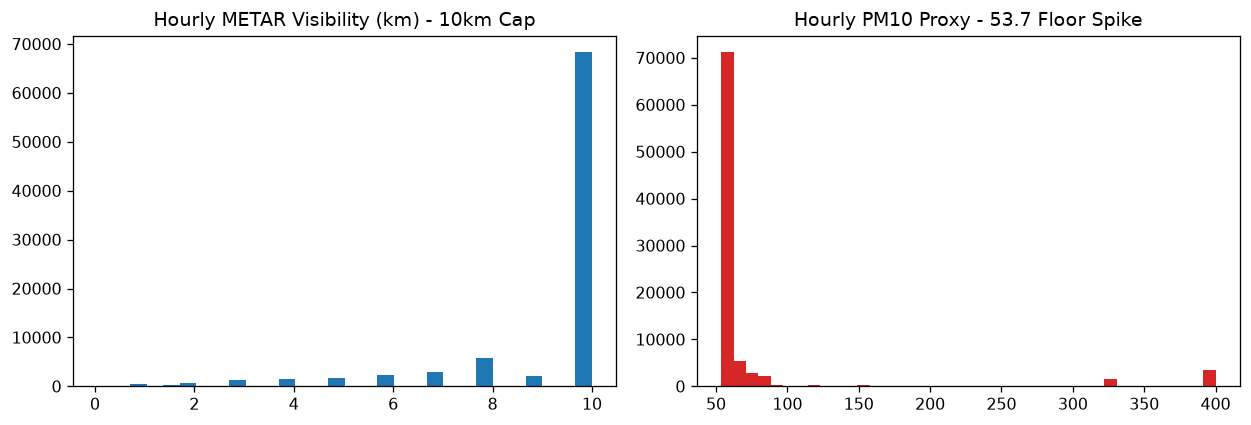

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(df['visibility_km'].dropna(), bins=30, color='#1f77b4'); axes[0].set_title('Hourly METAR Visibility (km) - 10km Cap')
axes[1].hist(df['pm10_calibrated_ugm3'].clip(0, 400), bins=40, color='#d62728'); axes[1].set_title('Hourly PM10 Proxy - 53.7 Floor Spike')
plt.tight_layout()

## 7. Issue 2 Audit: `2022–2024` Regime Shift & `sat_retrieved_pm10` Drift

In [7]:
df['year'] = df['ts'].dt.year
yr = df.groupby('year').agg(hours=('pm10_calibrated_ugm3','count'), dust_pct=('is_dust_event', lambda s: s.mean()*100), vis_lt5_pct=('visibility_km', lambda s: (s<5.0).mean()*100), pm10_mean=('pm10_calibrated_ugm3','mean'), sat_pm10=('sat_retrieved_pm10','mean'), cams_pm10=('nwp_cams_pm10','mean'))
print(yr.round(2).to_string())

      hours  dust_pct  vis_lt5_pct  pm10_mean  sat_pm10  cams_pm10
year                                                              
2015   8736     11.13         8.24     128.72     99.19      95.29
2016   8784      5.74         4.42      87.43     84.98      82.79
2017   8760      7.98         6.03     100.71     89.57      86.82
2018   8760      9.39         7.25     145.21     88.83      86.17
2019   8760      7.26         5.03      93.32     85.57      83.30
2020   8784      5.85         4.09      89.65     80.31      78.67
2021   8760      5.03         3.95      84.91     91.14      88.20
2022   8760     10.51         8.22     118.29    109.34     104.22
2023   8760      2.45         2.03      60.12    164.50     152.76
2024   8592      1.04         0.66      58.62    411.53     370.15


## 8. Annual Dust-Rate vs Satellite/CAMS Drift Visualization

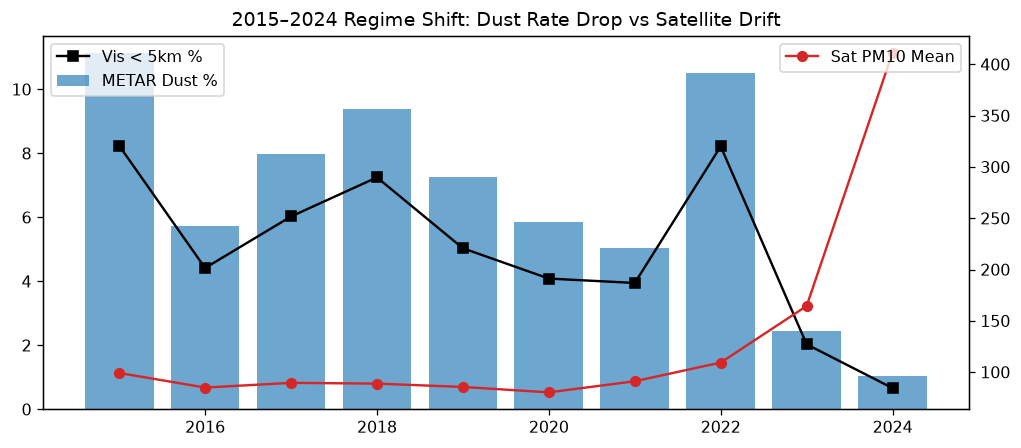

In [8]:
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.bar(yr.index, yr['dust_pct'], alpha=0.65, label='METAR Dust %')
ax1.plot(yr.index, yr['vis_lt5_pct'], marker='s', color='black', label='Vis < 5km %')
ax2 = ax1.twinx(); ax2.plot(yr.index, yr['sat_pm10'], marker='o', color='#d62728', label='Sat PM10 Mean')
ax1.set_title('2015–2024 Regime Shift: Dust Rate Drop vs Satellite Drift'); ax1.legend(loc='upper left'); ax2.legend(loc='upper right'); plt.tight_layout()

## 9. Hourly Train (70%) / 360h Gap / Val (15%) / 360h Gap / Test (15%) Split

In [9]:
N = len(df); GAP_H = 360
tr_end = int(N * 0.70); val_start = tr_end + GAP_H; val_end = int(N * 0.85); te_start = val_end + GAP_H
train_df = df.iloc[:tr_end]; val_df = df.iloc[val_start:val_end]; test_df = df.iloc[te_start:]
print(f'Train (70%): {len(train_df):,}h ({train_df["ts"].min()} -> {train_df["ts"].max()}) | Dust={train_df["is_dust_event"].mean()*100:.2f}%')
print(f'Val   (15%): {len(val_df):,}h ({val_df["ts"].min()} -> {val_df["ts"].max()}) | Dust={val_df["is_dust_event"].mean()*100:.2f}%')
print(f'Test  (15%): {len(test_df):,}h ({test_df["ts"].min()} -> {test_df["ts"].max()}) | Dust={test_df["is_dust_event"].mean()*100:.2f}%')

Train (70%): 61,219h (2015-01-02 00:00:00 -> 2021-12-26 18:00:00) | Dust=7.47%
Val   (15%): 12,758h (2022-01-10 19:00:00 -> 2023-06-26 08:00:00) | Dust=8.43%
Test  (15%): 12,759h (2023-07-11 09:00:00 -> 2024-12-23 23:00:00) | Dust=0.94%


## 10. 5-Fold Rolling-Origin CV Structure Inside 70% Hourly Train

In [10]:
n_tr = len(train_df); m_tr = int(n_tr * 0.40); st = (n_tr - m_tr) // 5
for f in range(5):
    a = m_tr + f*st - GAP_H; b = m_tr + f*st; c = b + st if f < 4 else n_tr
    print(f'CV Fold {f+1}: Train[0:{a:,}h] -> 360h Gap -> Val[{b:,}:{c:,}h] | Dust={train_df.iloc[b:c]["is_dust_event"].mean()*100:.2f}%')

CV Fold 1: Train[0:24,127h] -> 360h Gap -> Val[24,487:31,833h] | Dust=10.02%
CV Fold 2: Train[0:31,473h] -> 360h Gap -> Val[31,833:39,179h] | Dust=8.30%
CV Fold 3: Train[0:38,819h] -> 360h Gap -> Val[39,179:46,525h] | Dust=5.43%
CV Fold 4: Train[0:46,165h] -> 360h Gap -> Val[46,525:53,871h] | Dust=4.40%
CV Fold 5: Train[0:53,511h] -> 360h Gap -> Val[53,871:61,219h] | Dust=4.97%


## 11. Hourly Time Series Across Train / Val / Test

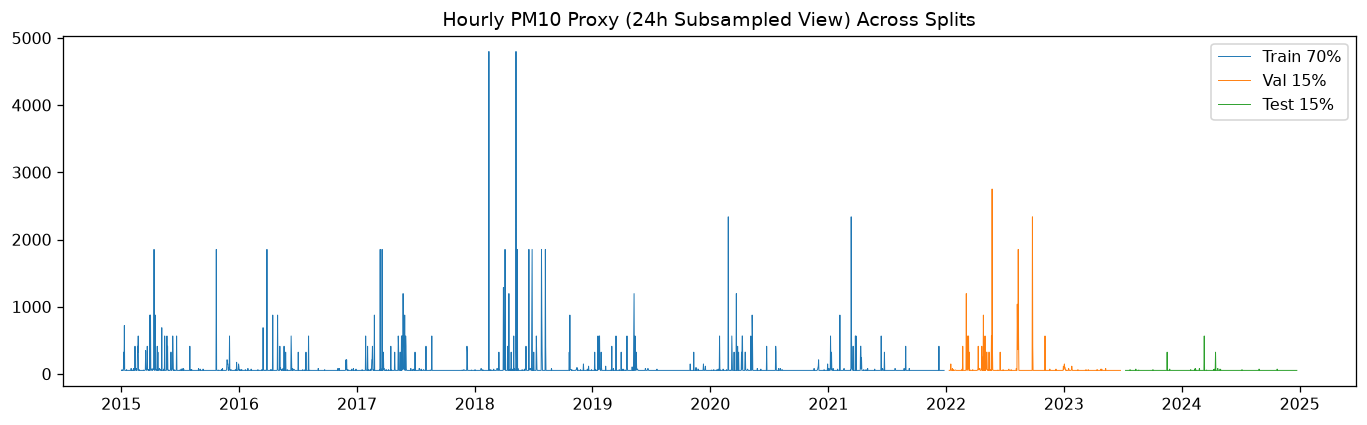

In [11]:
fig, ax = plt.subplots(figsize=(12, 3.8))
s_tr = train_df.iloc[::24]; s_va = val_df.iloc[::24]; s_te = test_df.iloc[::24]
ax.plot(s_tr['ts'], s_tr['pm10_calibrated_ugm3'], lw=0.6, label='Train 70%')
ax.plot(s_va['ts'], s_va['pm10_calibrated_ugm3'], lw=0.6, label='Val 15%')
ax.plot(s_te['ts'], s_te['pm10_calibrated_ugm3'], lw=0.6, label='Test 15%')
ax.set_title('Hourly PM10 Proxy (24h Subsampled View) Across Splits'); ax.legend(); plt.tight_layout()

## 12. Real KAPSARC Ground Sensor vs Hourly Visibility Proxy Audit

In [12]:
k_path = PROJECT_ROOT / '06_Data' / 'riyadh_kapsarc_sensor_pm10_daily.csv'
if k_path.exists():
    ks = pd.read_csv(k_path, sep=';'); ks['date'] = pd.to_datetime(ks['date']).dt.normalize()
    kd = ks[ks['indicator']=='Avg / Hourly'].groupby('date')['value'].mean().rename('real_sensor_pm10')
    df['date'] = df['ts'].dt.normalize()
    dd = df.groupby('date').agg(proxy=('pm10_calibrated_ugm3','mean'), cams=('nwp_cams_pm10','mean')).join(kd, how='inner')
    print(f'KAPSARC overlap: {len(dd)} days | Corr(real, proxy)={dd["real_sensor_pm10"].corr(dd["proxy"]):.3f} | Corr(real, CAMS)={dd["real_sensor_pm10"].corr(dd["cams"]):.3f}')

## 13. Real Sensor vs Proxy Scatter Plot (159 Overlapping Days)

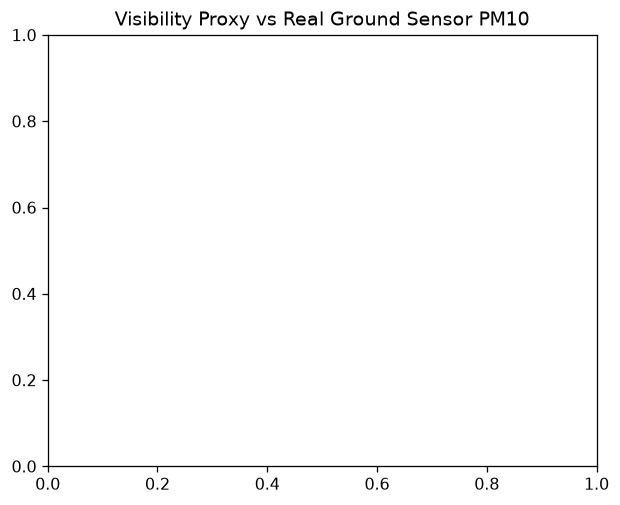

In [13]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
if 'dd' in locals():
    ax.scatter(dd['proxy'], dd['real_sensor_pm10'], s=18, alpha=0.65)
    ax.set_xlabel('METAR Visibility Proxy (ug/m3)'); ax.set_ylabel('Real KAPSARC Sensor PM10 (ug/m3)')
ax.set_title('Visibility Proxy vs Real Ground Sensor PM10'); plt.tight_layout()

## 14. Inspect `line_b_final_dataset.npz` Multi-Modal Tensors

In [14]:
print('seq_features:', npz['seq_features'].shape, 'mean=', round(float(npz['seq_features'].mean()),4))
print('nwp_grid:', npz['nwp_grid'].shape, 'satellite_grid:', npz['satellite_grid'].shape)
print('targets_pm10:', npz['targets_pm10'].shape, 'hazard_classes:', npz['hazard_classes'].shape)

seq_features: (400, 24, 6, 12) mean= -0.0819
nwp_grid: (400, 6, 16, 16) satellite_grid: (400, 3, 32, 32)
targets_pm10: (400, 6, 6) hazard_classes: (400, 6, 6)


## 15. Visualize NPZ Spatial Adjacency & Sample NWP/Satellite Grids

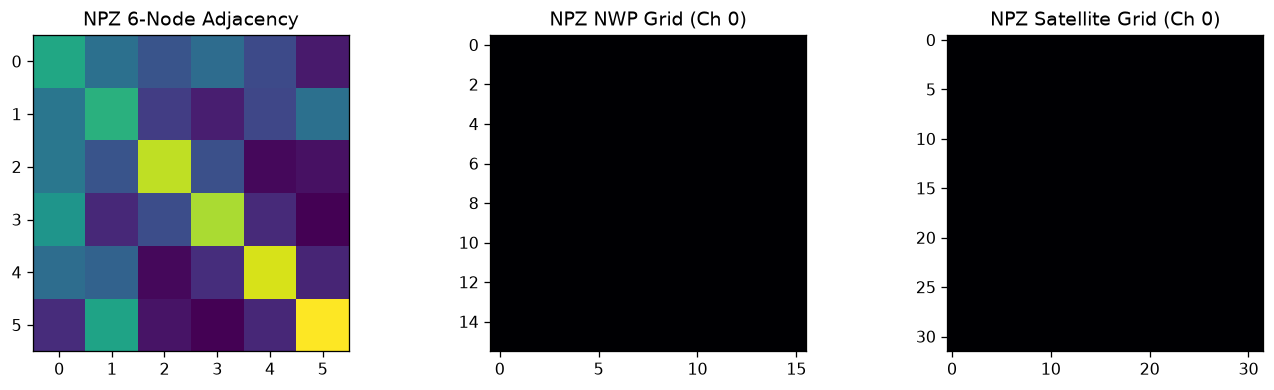

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].imshow(npz['adjacency_matrix'], cmap='viridis'); axes[0].set_title('NPZ 6-Node Adjacency')
axes[1].imshow(npz['nwp_grid'][0, 0], cmap='magma'); axes[1].set_title('NPZ NWP Grid (Ch 0)')
axes[2].imshow(npz['satellite_grid'][0, 0], cmap='inferno'); axes[2].set_title('NPZ Satellite Grid (Ch 0)')
plt.tight_layout()

## 16. Hourly Diurnal Cycle (Dust Rate & Wind Speed by UTC Hour)

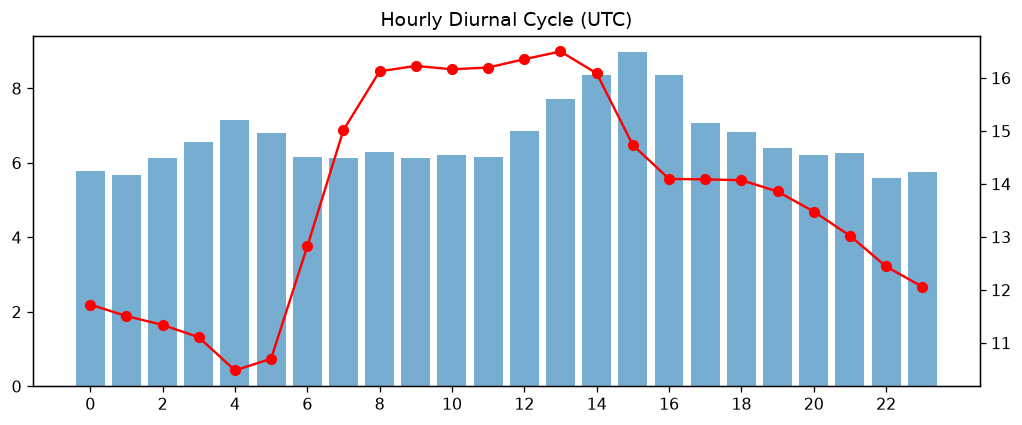

In [16]:
df['hour'] = df['ts'].dt.hour
hr = df.groupby('hour').agg(dust=('is_dust_event', lambda s: s.mean()*100), ws=('era5_wind_speed_10m','mean'), blh=('era5_blh_m','mean'))
fig, ax1 = plt.subplots(figsize=(9, 3.8))
ax1.bar(hr.index, hr['dust'], alpha=0.6, label='Dust %'); ax2 = ax1.twinx(); ax2.plot(hr.index, hr['ws'], color='red', marker='o', label='ERA5 Wind (m/s)')
ax1.set_title('Hourly Diurnal Cycle (UTC)'); ax1.set_xticks(range(0,24,2)); plt.tight_layout()

## 17. Diurnal x Monthly Dust Heatmap (Hourly Resolution)

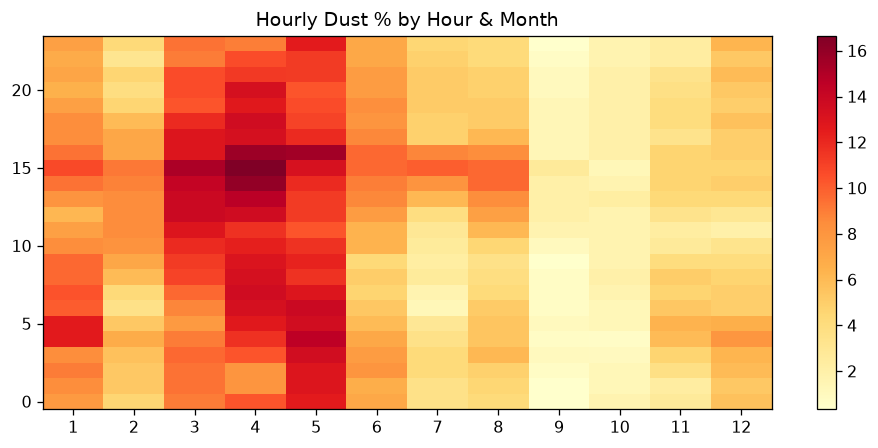

In [17]:
df['month'] = df['ts'].dt.month
piv = df.pivot_table(index='hour', columns='month', values='is_dust_event', aggfunc='mean')*100
fig, ax = plt.subplots(figsize=(8.5, 4))
im = ax.imshow(piv.values, aspect='auto', cmap='YlOrRd', origin='lower')
ax.set_xticks(range(12)); ax.set_xticklabels(range(1,13)); ax.set_title('Hourly Dust % by Hour & Month'); plt.colorbar(im, ax=ax); plt.tight_layout()

## 18. Wind Direction Polar Rose (Hourly All vs Dust)

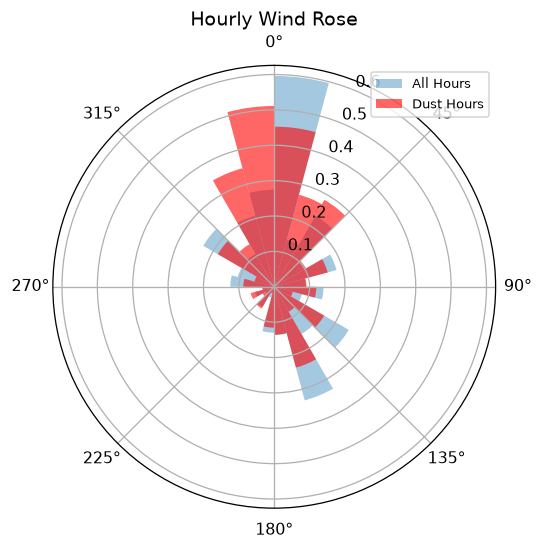

In [18]:
ang = np.deg2rad(df['drct'].dropna()); dang = np.deg2rad(df.loc[df['is_dust_event']==1, 'drct'].dropna())
fig, ax = plt.subplots(subplot_kw={'projection':'polar'}, figsize=(5, 5))
ax.hist(ang, bins=24, density=True, alpha=0.4, label='All Hours'); ax.hist(dang, bins=24, density=True, alpha=0.6, color='red', label='Dust Hours')
ax.set_theta_zero_location('N'); ax.set_theta_direction(-1); ax.set_title('Hourly Wind Rose'); ax.legend(loc='upper right', fontsize=8)

## 19. ERA5 Driver Distributions (Train 70% vs Test 15%)

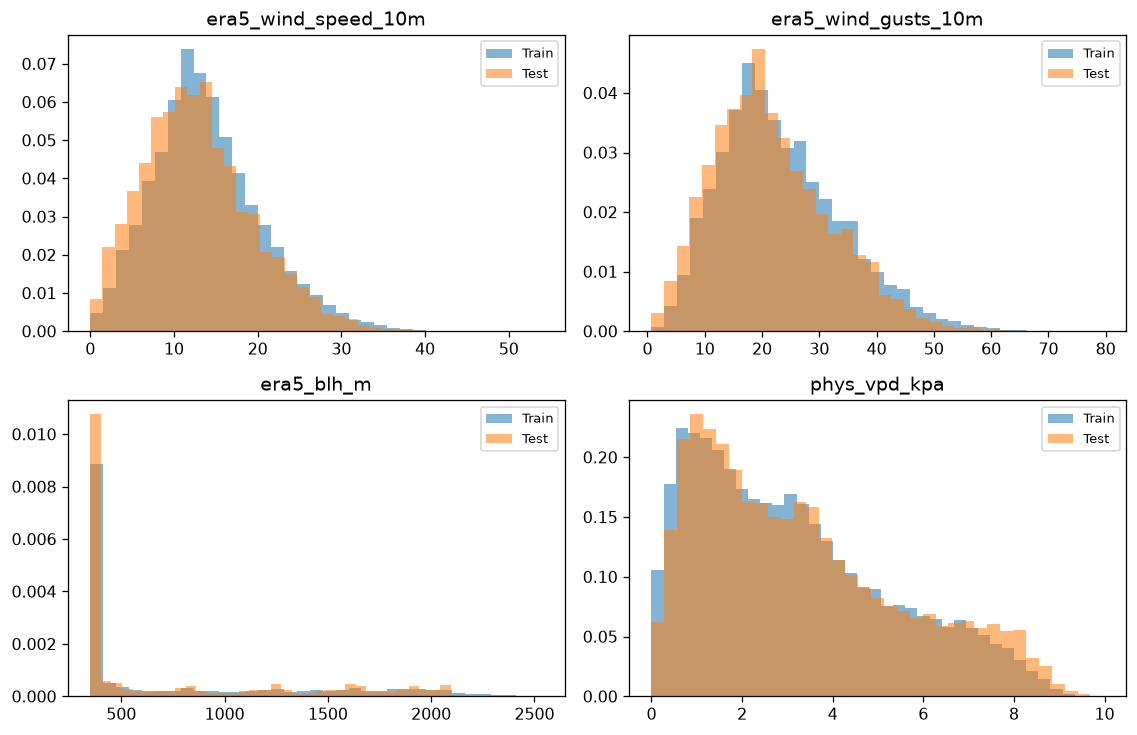

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
for ax, c in zip(axes.ravel(), ['era5_wind_speed_10m','era5_wind_gusts_10m','era5_blh_m','phys_vpd_kpa']):
    ax.hist(train_df[c].dropna(), bins=35, alpha=0.55, density=True, label='Train')
    ax.hist(test_df[c].dropna(), bins=35, alpha=0.55, density=True, label='Test')
    ax.set_title(c); ax.legend(fontsize=8)
plt.tight_layout()

## 20. Hourly Autocorrelation (1h to 168h / 7 Days)

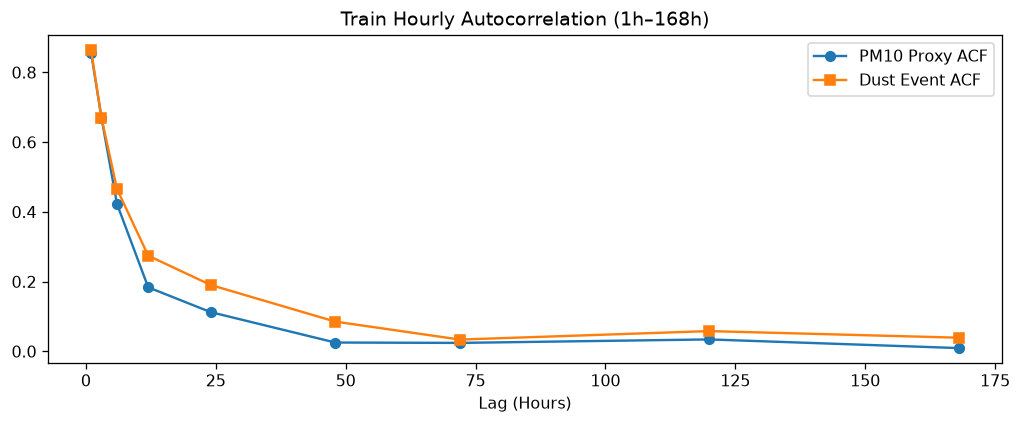

In [20]:
lags = [1, 3, 6, 12, 24, 48, 72, 120, 168]
acf_pm = [train_df['pm10_calibrated_ugm3'].autocorr(lag=k) for k in lags]
acf_ev = [train_df['is_dust_event'].autocorr(lag=k) for k in lags]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(lags, acf_pm, marker='o', label='PM10 Proxy ACF'); ax.plot(lags, acf_ev, marker='s', label='Dust Event ACF')
ax.set_title('Train Hourly Autocorrelation (1h–168h)'); ax.set_xlabel('Lag (Hours)'); ax.legend(); plt.tight_layout()

## 21. Train-Only Multi-Modal Correlation Heatmap

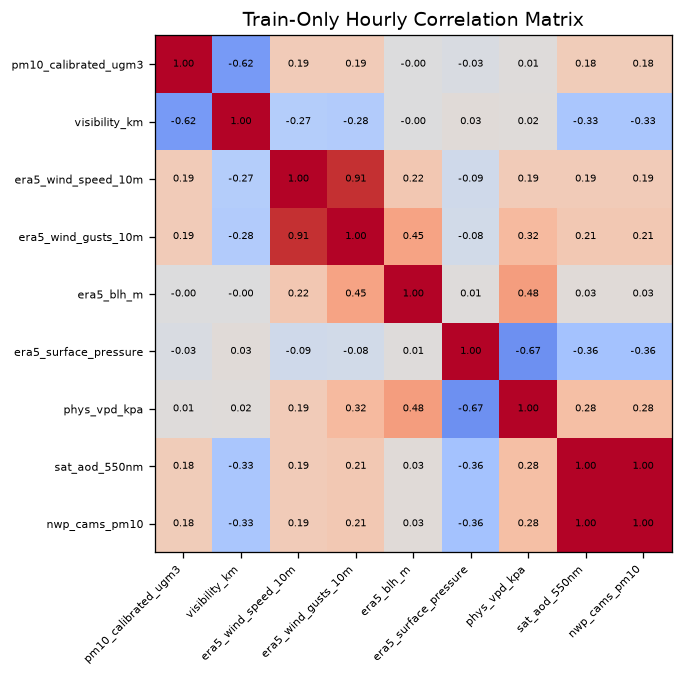

In [21]:
cols_c = ['pm10_calibrated_ugm3','visibility_km','era5_wind_speed_10m','era5_wind_gusts_10m','era5_blh_m','era5_surface_pressure','phys_vpd_kpa','sat_aod_550nm','nwp_cams_pm10']
corr = train_df[cols_c].corr().values
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(cols_c))); ax.set_xticklabels(cols_c, rotation=45, ha='right', fontsize=7)
ax.set_yticks(range(len(cols_c))); ax.set_yticklabels(cols_c, fontsize=7)
for i in range(len(cols_c)):
    for j in range(len(cols_c)): ax.text(j, i, f'{corr[i,j]:.2f}', ha='center', va='center', fontsize=6)
ax.set_title('Train-Only Hourly Correlation Matrix'); plt.tight_layout()

## 22. Pearson vs Spearman Non-Linearity Check (Train 70%)

In [22]:
rows = []
for c in ['visibility_km','era5_wind_speed_10m','era5_wind_gusts_10m','era5_blh_m','phys_vpd_kpa','sat_aod_550nm','nwp_cams_pm10']:
    sub = train_df[[c,'pm10_calibrated_ugm3']].dropna()
    rows.append({'Feature': c, 'Pearson': round(sub[c].corr(sub['pm10_calibrated_ugm3']),4), 'Spearman': round(spearmanr(sub[c], sub['pm10_calibrated_ugm3'])[0],4)})
print(pd.DataFrame(rows).to_string(index=False))

            Feature  Pearson  Spearman
      visibility_km  -0.6184   -0.9681
era5_wind_speed_10m   0.1913    0.2385
era5_wind_gusts_10m   0.1930    0.2659
         era5_blh_m  -0.0030    0.0649
       phys_vpd_kpa   0.0105    0.0037
      sat_aod_550nm   0.1827    0.3128
      nwp_cams_pm10   0.1827    0.3128


## 23. WMO PM10 Severity Tier Counts (Raw Hourly Proxy)

In [23]:
bins = [0, 50, 150, 300, 500, 10000]; lbls = ['Normal(<50)','Mod(50-150)','Elev(150-300)','Sev(300-500)','Ext(>500)']
print(pd.cut(df['pm10_calibrated_ugm3'], bins=bins, labels=lbls).value_counts().sort_index().to_string())

pm10_calibrated_ugm3
Normal(<50)          0
Mod(50-150)      82217
Elev(150-300)      290
Sev(300-500)      2713
Ext(>500)         2236


## 24. Hourly Split Summary Table

In [24]:
print(pd.DataFrame([{'Split':'Train_70','Hours':len(train_df),'Dust%':round(train_df['is_dust_event'].mean()*100,2)},{'Split':'Val_15','Hours':len(val_df),'Dust%':round(val_df['is_dust_event'].mean()*100,2)},{'Split':'Test_15','Hours':len(test_df),'Dust%':round(test_df['is_dust_event'].mean()*100,2)}]).to_string(index=False))

   Split  Hours  Dust%
Train_70  61219   7.47
  Val_15  12758   8.43
 Test_15  12759   0.94


## 25. Notebook 00 Summary

In [25]:
print('NB00 Complete: All 4 data issues quantified at hourly resolution + line_b_final_dataset.npz inspected. Next: NB01 fixes all cleanable data issues.')

NB00 Complete: All 4 data issues quantified at hourly resolution + line_b_final_dataset.npz inspected. Next: NB01 fixes all cleanable data issues.
